# Auditing Causal Credit Recourse in P2P Debt Consolidation

Reproducible experiments for the paper on the identifiability and robustness of contract-based recourse, using LendingClub debt consolidation loans.

**Research questions**

- **RQ1. Attribution robustness:** does the Intrinsic Causal Contribution (ICC) ranking survive plausible changes to the causal graph?
- **RQ2. Identifiability:** which contract levers have enough independent variation in the data to support a recommendation?
- **RQ3. Population recourse:** across all model-flagged loans, how often does a contract-consistent change bring risk under the threshold, at what cost, and does it beat a negative control?
- **RQ4. Causal cross-check:** do the model's implied effects agree with Double Machine Learning (DML), and how sensitive are they to unobserved confounding?

**Scope of inference.** The data contain funded loans only. "Flagged" means flagged by our model on funded loans. Nothing here estimates outcomes for applicants LendingClub actually rejected.

**Data.** [Kaggle: LendingClub 2007-2020Q1](https://www.kaggle.com/datasets/ethon0426/lending-club-20072020q1). Place `Loan_status_2007-2020Q3.gzip` next to this notebook, or set the `LENDINGCLUB_CSV` environment variable. The data file is not part of this repository.

**Environment.** Python 3.13, DoWhy 0.14. Exact versions are printed below. Set `FAST = True` for a quick smoke run.

## 1. Setup

In [1]:
import itertools, os, time, warnings
from pathlib import Path

warnings.filterwarnings('ignore')
os.environ.setdefault('TQDM_DISABLE', '1')

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

FAST = bool(int(os.environ.get('FAST', '0')))
DATA_PATH = Path(os.environ.get('LENDINGCLUB_CSV', 'Loan_status_2007-2020Q3.gzip'))
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

MODEL_SEEDS = [0, 1] if FAST else [0, 1, 2, 3, 4]
ICC_SEEDS = [0] if FAST else [0, 1, 2]
ICC_SAMPLE = 3000 if FAST else 8000
N_BOOT = 100 if FAST else 500
PC_BOOTSTRAPS = 5 if FAST else 30
NOTEARS_RUNS = 1 if FAST else 3
DISCOVERY_SAMPLE = 5000
PRIMARY_FLAG_RATE = 0.20
FLAG_RATES = [0.10, 0.20, 0.30]
MIN_LOAN = 1000

# Colours: one sequential blue for the marks, grey for controls, dark ink for text.
BLUE, GREY, INK, MUTED = '#2563A8', '#9AA3AE', '#1F2933', '#616E7C'
plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 300, 'font.size': 9, 'axes.edgecolor': MUTED,
    'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': INK, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'axes.grid.axis': 'x', 'grid.color': '#E4E7EB', 'axes.axisbelow': True,
})

def save_table(df, name, index=True):
    df.to_csv(RESULTS / f'{name}.csv', index=index)
    return df

def save_fig(fig, name):
    fig.savefig(RESULTS / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(RESULTS / f'{name}.png', bbox_inches='tight')

from importlib.metadata import version
import sys
print('python', sys.version.split()[0], '| FAST =', FAST)
print({p: version(p) for p in ['dowhy', 'causal-learn', 'notears', 'catboost', 'shap', 'torch',
                               'scikit-learn', 'pandas', 'numpy', 'scipy', 'networkx']})

python 3.13.18 | FAST = False
{'dowhy': '0.14', 'causal-learn': '0.1.4.8', 'notears': '3.0', 'catboost': '1.2.10', 'shap': '0.54.1', 'torch': '2.15.0', 'scikit-learn': '1.9.1', 'pandas': '3.1.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'networkx': '3.7'}


## 2. Data

Only variables known at application time enter the feature set. `last_pymnt_d` is read solely to build a horizon-aligned label for the term analysis in Section 8, and is never a feature.

In [2]:
USECOLS = ['loan_amnt', 'term', 'int_rate', 'installment', 'sub_grade', 'annual_inc', 'issue_d', 'loan_status',
           'purpose', 'acc_open_past_24mths', 'tot_cur_bal', 'revol_bal', 'fico_range_low', 'fico_range_high',
           'dti', 'emp_length', 'home_ownership', 'earliest_cr_line', 'verification_status', 'revol_util',
           'open_acc', 'total_acc', 'mort_acc', 'last_pymnt_d']

def detect_compression(path):
    # The Kaggle file is a plain CSV despite its .gzip extension.
    with open(path, 'rb') as f:
        return 'gzip' if f.read(2) == b'\x1f\x8b' else None

n_raw, chunks = 0, []
for chunk in pd.read_csv(DATA_PATH, usecols=USECOLS, compression=detect_compression(DATA_PATH),
                         chunksize=200_000, low_memory=False):
    n_raw += len(chunk)
    chunks.append(chunk[chunk.purpose == 'debt_consolidation'].drop(columns='purpose'))
raw = pd.concat(chunks, ignore_index=True)
del chunks

for col in ['int_rate', 'revol_util']:
    raw[col] = pd.to_numeric(raw[col].astype(str).str.replace('%', '').str.strip(), errors='coerce')
raw['term'] = raw.term.astype(str).str.extract(r'(\d+)')[0].astype(float)
raw['issue'] = pd.to_datetime(raw.issue_d, format='%b-%Y', errors='coerce')
raw['year'] = raw.issue.dt.year
raw['month'] = raw.issue.dt.month
raw['quarter'] = raw.issue.dt.to_period('Q').astype(str)

COMPLETED = raw.loan_status.isin(['Fully Paid', 'Charged Off'])
display(save_table(pd.Series({
    'all loans': n_raw,
    'debt consolidation': len(raw),
    'of which completed (Fully Paid / Charged Off)': int(COMPLETED.sum()),
    'default rate among completed': round((raw.loan_status[COMPLETED] == 'Charged Off').mean(), 4),
    'term values': sorted(raw.term.dropna().unique().tolist()),
}, name='value').to_frame(), 'table_cohort_flow'))

,value
all loans,2925493
debt consolidation,1638058
of which completed (Fully Paid / Charged Off),1063459
default rate among completed,0.2064
term values,"[36.0, 60.0]"


### 2.1 Which vintages are safe to use?

Keeping only completed loans from recent vintages over-represents early defaults, because many surviving loans are still open. We therefore use only vintages where both terms have effectively completed.

In [3]:
grp = raw.groupby(['year', 'term'])
maturity = pd.DataFrame({
    'loans': grp.size(),
    'share_completed': grp.apply(lambda x: x.loan_status.isin(['Fully Paid', 'Charged Off']).mean(), include_groups=False),
    'default_rate_if_completed': grp.apply(
        lambda x: (x.loan_status[x.loan_status.isin(['Fully Paid', 'Charged Off'])] == 'Charged Off').mean(),
        include_groups=False),
}).round(3)
display(save_table(maturity.unstack('term'), 'table_vintage_maturity'))

loans           share_completed        default_rate_if_completed  \
term      36.0      60.0            36.0   60.0                      36.0   
year                                                                        
2007     207.0       NaN           0.377    NaN                     0.192   
2008     976.0       NaN           0.641    NaN                     0.168   
2009    2194.0       NaN           0.904    NaN                     0.123   
2010    4123.0    1606.0           0.930  0.924                     0.101   
2011    6609.0    4061.0           1.000  1.000                     0.109   
2012   24310.0    6501.0           1.000  1.000                     0.143   
2013   57565.0   23075.0           1.000  1.000                     0.126   
2014   94822.0   48184.0           1.000  1.000                     0.144   
2015  161068.0   88952.0           1.000  0.877                     0.157   
2016  178058.0   70841.0           1.000  0.730                     0.167   
2017  168738.0   76345.0           0.781  0.553                     0.180   
2018  170074.0   89568.0           0.432  0.348                     0.204   
2019  179260.0  102615.0           0.159  0.119                     0.170   
2020   51485.0   26821.0           0.030  0.021                     0.014   

             
term   60.0  
year         
2007    NaN  
2008    NaN  
2009    NaN  
2010  0.215  
2011  0.247  
2012  0.289  
2013  0.258  
2014  0.273  
2015  0.323  
2016  0.357  
2017  0.356  
2018  0.355  
2019  0.238  
2020  0.019

In [4]:
SUBGRADES = {f'{g}{i}': n * 5 + i - 1 for n, g in enumerate('ABCDEFG') for i in range(1, 6)}
EMP = {'< 1 year': 0, '1 year': 1, **{f'{i} years': i for i in range(2, 10)}, '10+ years': 10}

df = raw[COMPLETED].copy()
del raw
df['y'] = (df.loan_status == 'Charged Off').astype(int)
df['sg'] = df.sub_grade.map(SUBGRADES).astype(float)  # ordinal A1..G5, never encoded with the outcome
df['fico'] = (df.fico_range_low + df.fico_range_high) / 2
df['emp'] = df.emp_length.map(EMP)
df['home'] = df.home_ownership.map({'RENT': 0, 'MORTGAGE': 1, 'OWN': 2}).fillna(3)
df['verified'] = df.verification_status.map({'Not Verified': 0, 'Source Verified': 1, 'Verified': 2})
first_credit = pd.to_datetime(df.earliest_cr_line, format='%b-%Y', errors='coerce')
df['hist_months'] = (df.issue.dt.year - first_credit.dt.year) * 12 + (df.issue.dt.month - first_credit.dt.month)
df['pti'] = df.installment * 12 / df.annual_inc.clip(lower=1000)
df['q_idx'] = df.year * 4 + df.issue.dt.quarter

# Horizon-aligned label: charged off with the last payment within 31 months, i.e. charge-off by about month 36.
last_paid = pd.to_datetime(df.last_pymnt_d, format='%b-%Y', errors='coerce')
months_paid = (last_paid.dt.year - df.issue.dt.year) * 12 + (last_paid.dt.month - df.issue.dt.month)
df['y36'] = ((df.y == 1) & (months_paid.isna() | (months_paid <= 31))).astype(int)

PRE = ['annual_inc', 'dti', 'fico', 'emp', 'home', 'verified', 'revol_bal', 'revol_util', 'open_acc',
       'total_acc', 'mort_acc', 'tot_cur_bal', 'acc_open_past_24mths', 'hist_months']
CONTRACT = ['loan_amnt', 'term', 'int_rate', 'installment', 'pti', 'sg']
FEATURES = PRE + CONTRACT

fit = df[df.year.isin([2012, 2013])]
cal = df[(df.year == 2014) & (df.month <= 6)]
test = df[(df.year == 2014) & (df.month > 6)].copy()
display(save_table(pd.DataFrame({
    'period': ['2012-2013', '2014 H1', '2014 H2'],
    'loans': [len(fit), len(cal), len(test)],
    'default_rate': [fit.y.mean(), cal.y.mean(), test.y.mean()],
    'default_rate_36m': [fit.y36.mean(), cal.y36.mean(), test.y36.mean()],
}, index=['fit', 'calibration', 'test']).round(4), 'table_splits'))

,period,loans,default_rate,default_rate_36m
fit,2012-2013,111451,0.1664,0.1398
calibration,2014 H1,60784,0.1833,0.1529
test,2014 H2,82211,0.1901,0.1592


## 3. RQ2: Which contract levers are identifiable?

If a lever is almost fully determined by other variables, the data contain little evidence about changing it alone. We measure how much of each lever is left after conditioning on `sub_grade x quarter x term`.

In [5]:
cell = ['sub_grade', 'quarter', 'term']
all_rows = df[df.int_rate.notna()]

def r_squared(frame, target, keys):
    residual = frame[target] - frame.groupby(keys)[target].transform('mean')
    return 1 - residual.var() / frame[target].var()

rows = []
for lever in ['int_rate', 'loan_amnt']:
    within = all_rows.groupby(cell)[lever].agg(['std', 'mean', 'count']).query('count >= 30')
    rows.append({'lever': lever,
                 'R2 ~ sub_grade': r_squared(all_rows, lever, ['sub_grade']),
                 'R2 ~ sub_grade x quarter': r_squared(all_rows, lever, ['sub_grade', 'quarter']),
                 'R2 ~ sub_grade x quarter x term': r_squared(all_rows, lever, cell),
                 'median within-cell std': within['std'].median(),
                 'median within-cell CV': (within['std'] / within['mean']).median()})
display(save_table(pd.DataFrame(rows).set_index('lever').round(4), 'table_lever_identifiability'))

def annuity(principal, annual_rate_pct, months):
    r = annual_rate_pct / 1200
    return principal * r / (1 - (1 + r) ** -months)

implied = annuity(all_rows.loan_amnt, all_rows.int_rate, all_rows.term)
ss_res = ((implied - all_rows.installment) ** 2).sum()
ss_tot = ((all_rows.installment - all_rows.installment.mean()) ** 2).sum()
print(f'Installment vs annuity formula: R2 = {1 - ss_res / ss_tot:.5f}, '
      f'median relative error = {((implied - all_rows.installment).abs() / all_rows.installment).median():.6f}')
print('Mean ordinal sub_grade by term:', all_rows.groupby('term').sg.mean().round(2).to_dict())

,R2 ~ sub_grade,R2 ~ sub_grade x quarter,R2 ~ sub_grade x quarter x term,median within-cell std,median within-cell CV
lever,,,,,
int_rate,0.9454,0.9969,0.9969,0.0665,0.0042
loan_amnt,0.0287,0.0465,0.1596,7845.0205,0.4501


Installment vs annuity formula: R2 = 0.99949, median relative error = 0.000011
Mean ordinal sub_grade by term: {36.0: 9.23, 60.0: 15.39}


**How this is used.** `installment` is computed from the contract rather than learned as a node with noise. The interest rate is only reported as an extrapolation. Loan amount is the primary lever, and term is analysed separately because longer terms carry worse grades and longer exposure.

## 4. Baseline risk model

CatBoost is trained at natural prevalence and calibrated with Platt scaling on a later period. For comparison, the same model is also trained on a 50/50 balanced sample, the design used in earlier work, and scored on the same test set.

In [6]:
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

def expected_calibration_error(y, p, bins=10):
    groups = pd.DataFrame({'y': np.asarray(y), 'p': p})
    groups['bin'] = pd.qcut(groups.p, bins, duplicates='drop')
    g = groups.groupby('bin', observed=True)
    return float((g.size() / len(groups) * (g.y.mean() - g.p.mean()).abs()).sum())

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

class RiskModel:
    '''Seed-averaged CatBoost with a Platt layer fitted on a later period.'''
    def __init__(self, features, label, seeds):
        self.features, self.label = features, label
        self.members = [CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6,
                                           random_seed=s, verbose=0) for s in seeds]
    def fit(self, train, calibration=None):
        for m in self.members:
            m.fit(train[self.features], train[self.label])
        self.platt = None
        if calibration is not None:
            self.platt = LogisticRegression(C=1e6).fit(
                logit(self.raw(calibration)).reshape(-1, 1), calibration[self.label])
        return self
    def raw(self, X):
        return np.mean([m.predict_proba(X[self.features])[:, 1] for m in self.members], axis=0)
    def predict(self, X):
        p = self.raw(X)
        return p if self.platt is None else self.platt.predict_proba(logit(p).reshape(-1, 1))[:, 1]

def score(y, p):
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'Brier': brier_score_loss(y, p), 'ECE': expected_calibration_error(y, p),
            'mean predicted': p.mean(), 'observed': np.mean(y)}

t0 = time.time()
risk = RiskModel(FEATURES, 'y', MODEL_SEEDS).fit(fit, cal)
risk36 = RiskModel(FEATURES, 'y36', MODEL_SEEDS).fit(fit, cal)

per_seed = pd.DataFrame([score(test.y, RiskModel(FEATURES, 'y', [s]).fit(fit, cal).predict(test)) for s in MODEL_SEEDS])

balanced_fit = pd.concat([fit[fit.y == 0].sample(int(fit.y.sum()), random_state=0), fit[fit.y == 1]])
balanced = RiskModel(FEATURES, 'y', MODEL_SEEDS).fit(balanced_fit)

p_test = risk.predict(test)
comparison = pd.DataFrame({
    'natural + Platt (ensemble)': score(test.y, p_test),
    'natural + Platt (seed mean)': per_seed.mean(),
    'natural + Platt (seed std)': per_seed.std(),
    'balanced 50/50, uncalibrated': score(test.y, balanced.predict(test)),
    'natural + Platt, 36-month label': score(test.y36, risk36.predict(test)),
}).T
display(save_table(comparison.round(4), 'table_prediction'))
print(f'{time.time() - t0:.0f}s')

,ROC-AUC,PR-AUC,Brier,ECE,mean predicted,observed
natural + Platt (ensemble),0.6992,0.3369,0.1422,0.0068,0.1840,0.1901
natural + Platt (seed mean),0.6981,0.3352,0.1424,0.0075,0.1840,0.1901
natural + Platt (seed std),0.0003,0.0008,0.0000,0.0006,0.0005,0.0000
"balanced 50/50, uncalibrated",0.6982,0.3367,0.2284,0.2824,0.4725,0.1901
"natural + Platt, 36-month label",0.6870,0.2783,0.1260,0.0064,0.1530,0.1592


139s


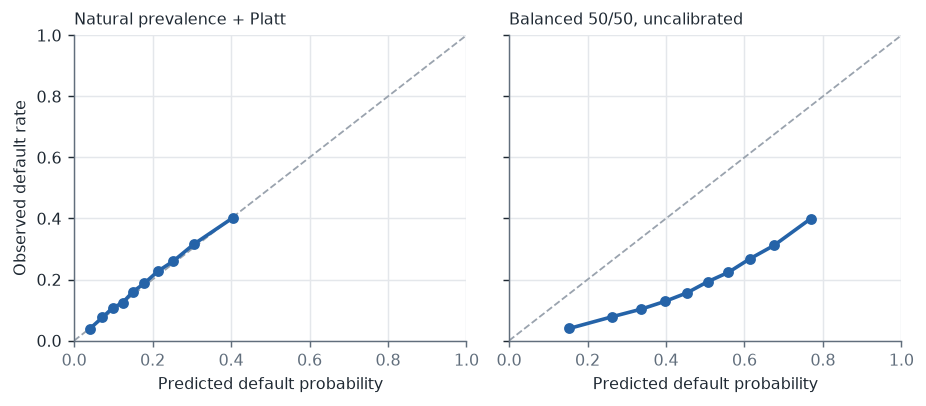

In [7]:
frame = pd.DataFrame({'y': test.y.values, 'natural': p_test, 'balanced': balanced.predict(test)})
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), sharex=True, sharey=True)
for ax, col, title in zip(axes, ['natural', 'balanced'], ['Natural prevalence + Platt', 'Balanced 50/50, uncalibrated']):
    g = frame.groupby(pd.qcut(frame[col], 10, duplicates='drop'), observed=True).agg(p=(col, 'mean'), y=('y', 'mean'))
    ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls='--')
    ax.plot(g.p, g.y, color=BLUE, lw=2, marker='o', ms=5)
    ax.set_title(title, fontsize=9, loc='left')
    ax.set_xlabel('Predicted default probability')
    ax.grid(axis='y', color='#E4E7EB')
axes[0].set_ylabel('Observed default rate')
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1)
fig.tight_layout(); save_fig(fig, 'fig_calibration'); plt.show()

## 5. Causal discovery with background knowledge

Discovery runs only on pre-test data with complete features (2013 to 2014 H1). Temporal tiers restrict which edges are allowed:

`vintage -> borrower profile -> loan_amnt, term -> sub_grade -> int_rate -> default`

`installment` is excluded because it is a deterministic function of the contract. We compare PC with and without tiers, and NOTEARS-MLP with its edges checked against the tiers. Edge frequencies are bootstrap-based. Fisher-z treats the binary outcome and ordinal grades as continuous, which is an approximation. Because `sg` and `int_rate` are nearly deterministic given each other, conditioning on one can remove the other's edge to `y`. A missing `sg -> y` or `int_rate -> y` is therefore not evidence of no effect.

In [8]:
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge

PROFILE = ['annual_inc', 'dti', 'fico', 'revol_bal', 'revol_util', 'open_acc', 'total_acc', 'mort_acc',
           'tot_cur_bal', 'acc_open_past_24mths', 'hist_months']
TIERS = {'q_idx': 0, **{v: 1 for v in PROFILE}, 'loan_amnt': 2, 'term': 2, 'sg': 3, 'int_rate': 4, 'y': 5}
NODES = list(TIERS)
discovery_pool = df[(df.year == 2013) | ((df.year == 2014) & (df.month <= 6))][NODES].dropna().astype(float)

def run_pc(sample, use_tiers):
    X = ((sample - sample.mean()) / sample.std()).values
    kwargs = dict(alpha=0.01, indep_test='fisherz', node_names=NODES, show_progress=False, verbose=False)
    if use_tiers:
        names = pc(X[:50], **kwargs).G.get_nodes()
        bk = BackgroundKnowledge()
        for node in names:
            bk.add_node_to_tier(node, TIERS[node.get_name()])
        kwargs['background_knowledge'] = bk
    g = pc(X, **kwargs).G
    directed, undirected = [], []
    for e in g.get_graph_edges():
        a, b = e.get_node1().get_name(), e.get_node2().get_name()
        text = str(e)
        if '-->' in text: directed.append((a, b))
        elif '<--' in text: directed.append((b, a))
        else: undirected.append((a, b))
    return directed, undirected

def edge_frequency(use_tiers):
    counts = pd.DataFrame(0.0, index=NODES, columns=NODES)
    for b in range(PC_BOOTSTRAPS):
        sample = discovery_pool.sample(DISCOVERY_SAMPLE, replace=True, random_state=b)
        directed, undirected = run_pc(sample, use_tiers)
        for a, c in directed:
            counts.loc[a, c] += 1
        for a, c in undirected:
            counts.loc[a, c] += .5; counts.loc[c, a] += .5
    return counts / PC_BOOTSTRAPS

t0 = time.time()
freq_tiers, freq_free = edge_frequency(True), edge_frequency(False)
print(f'PC bootstraps: {time.time() - t0:.0f}s')

PC bootstraps: 122s


In [9]:
import torch
from notears.nonlinear import NotearsMLP, notears_nonlinear
torch.set_default_dtype(torch.double)

NOTEARS_THRESHOLD = 0.1
weights = []
t0 = time.time()
for seed in range(NOTEARS_RUNS):
    np.random.seed(seed); torch.manual_seed(seed)
    sample = discovery_pool.sample(DISCOVERY_SAMPLE, random_state=seed)
    X = ((sample - sample.min()) / (sample.max() - sample.min())).values
    model = NotearsMLP(dims=[X.shape[1], 16, 1], bias=True)
    weights.append(notears_nonlinear(model, X, lambda1=1e-3, lambda2=1e-3, max_iter=20, w_threshold=0.0))
print(f'NOTEARS: {time.time() - t0:.0f}s')

freq_notears = pd.DataFrame(np.mean([np.abs(W) > NOTEARS_THRESHOLD for W in weights], axis=0), index=NODES, columns=NODES)
tier_rank = np.array([TIERS[n] for n in NODES])
violates = tier_rank[:, None] > tier_rank[None, :]
raw_edges = np.mean([(np.abs(W) > NOTEARS_THRESHOLD).sum() for W in weights])
raw_violations = np.mean([((np.abs(W) > NOTEARS_THRESHOLD) & violates).sum() for W in weights])
print(f'NOTEARS edges: {raw_edges:.1f}; against temporal order: {raw_violations:.1f} ({raw_violations / max(raw_edges, 1):.1%})')
freq_notears_masked = freq_notears.where(~violates, 0.0)

KEY_EDGES = [('int_rate', 'sg'), ('sg', 'int_rate'), ('sg', 'y'), ('int_rate', 'y'), ('loan_amnt', 'y'), ('term', 'y'),
             ('loan_amnt', 'sg'), ('term', 'sg'), ('term', 'int_rate'), ('fico', 'sg'), ('fico', 'y'),
             ('annual_inc', 'loan_amnt'), ('acc_open_past_24mths', 'y'), ('tot_cur_bal', 'y'), ('y', 'sg'), ('y', 'int_rate')]
display(save_table(pd.DataFrame({
    'PC, no tiers': [freq_free.loc[e] for e in KEY_EDGES],
    'PC, tiers': [freq_tiers.loc[e] for e in KEY_EDGES],
    'NOTEARS, unconstrained': [freq_notears.loc[e] for e in KEY_EDGES],
    'NOTEARS, tier mask': [freq_notears_masked.loc[e] for e in KEY_EDGES],
}, index=[f'{a} -> {b}' for a, b in KEY_EDGES]).round(2), 'table_key_edges'))

def skeleton(freq, cut=0.5):
    f = (freq + freq.T).values >= cut
    return {frozenset((NODES[i], NODES[j])) for i in range(len(NODES)) for j in range(i) if f[i, j]}
a, b = skeleton(freq_tiers), skeleton(freq_notears_masked)
print(f'Skeleton Jaccard, PC with tiers vs NOTEARS with mask: {len(a & b) / max(len(a | b), 1):.2f} ({len(a)} vs {len(b)} edges)')

NOTEARS: 410s
NOTEARS edges: 25.3; against temporal order: 5.3 (21.1%)


,"PC, no tiers","PC, tiers","NOTEARS, unconstrained","NOTEARS, tier mask"
int_rate -> sg,0.55,0.00,0.67,0.00
sg -> int_rate,0.45,1.00,0.33,0.33
sg -> y,0.15,0.40,0.67,0.67
int_rate -> y,0.03,0.03,0.67,0.67
loan_amnt -> y,0.00,0.00,0.00,0.00
term -> y,0.28,0.90,0.67,0.67
loan_amnt -> sg,0.00,0.00,0.00,0.00
term -> sg,0.47,1.00,0.00,0.00
term -> int_rate,0.00,0.00,0.00,0.00
fico -> sg,0.07,0.90,0.33,0.33


Skeleton Jaccard, PC with tiers vs NOTEARS with mask: 0.17 (36 vs 20 edges)


In [10]:
# Consensus graph: edges kept in at least 70% of PC-with-tiers bootstraps, then any cycle broken at its weakest edge.
CONSENSUS_CUT = 0.7
consensus = nx.DiGraph()
consensus.add_nodes_from(NODES)
for u, v in itertools.combinations(NODES, 2):
    if freq_tiers.loc[u, v] + freq_tiers.loc[v, u] >= CONSENSUS_CUT:
        a, c = (u, v) if freq_tiers.loc[u, v] >= freq_tiers.loc[v, u] else (v, u)
        consensus.add_edge(a, c, weight=freq_tiers.loc[a, c] + freq_tiers.loc[c, a])
while not nx.is_directed_acyclic_graph(consensus):
    weakest = min(nx.find_cycle(consensus), key=lambda e: consensus.edges[e[0], e[1]]['weight'])
    consensus.remove_edge(weakest[0], weakest[1])
print('Parents of y:', sorted(consensus.predecessors('y')))
print('Ancestors of y:', sorted(nx.ancestors(consensus, 'y')))
save_table(nx.to_pandas_edgelist(consensus).round(2), 'table_consensus_edges', index=False)
display(nx.to_pandas_edgelist(consensus).round(2))

Parents of y: ['term']
Ancestors of y: ['term']


,source,target,weight
0,q_idx,sg,0.80
1,annual_inc,loan_amnt,1.00
2,dti,annual_inc,1.00
3,dti,revol_util,0.93
4,fico,loan_amnt,1.00
5,fico,sg,0.90
6,fico,int_rate,1.00
7,revol_bal,annual_inc,0.90
8,revol_bal,loan_amnt,1.00
9,revol_util,fico,1.00


## 6. RQ1: How robust is ICC to the graph?

We fit DoWhy-GCM on the seven variables of the earlier learned graph and change only the assumptions about orientation.

| Graph | Assumption |
|---|---|
| G0 | Earlier learned graph: `int_rate -> sub_grade -> y` |
| G1 | Documented order: `sub_grade -> int_rate`, default depends on grade |
| G2 | `sub_grade -> int_rate -> y`, grade acts only through the rate |
| G3 | `sub_grade -> int_rate`, both affect default |

Each graph runs on two cohorts: the 50/50 balanced sample used earlier, and a natural-prevalence sample from matured vintages. SHAP and ICC answer different questions: SHAP attributes a fitted model's predictions, and ICC attributes outcome uncertainty to each node's noise under an assumed graph. A difference in their rankings therefore does not show that either one is wrong.

In [11]:
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph, FalsifyConst
from dowhy.gcm.config import disable_progress_bars
disable_progress_bars()

ICC_VARS = ['annual_inc', 'installment', 'int_rate', 'sg', 'acc_open_past_24mths', 'revol_bal', 'tot_cur_bal']
COMMON = [('annual_inc', 'installment'), ('revol_bal', 'tot_cur_bal'), ('acc_open_past_24mths', 'y'), ('tot_cur_bal', 'y')]
GRAPHS = {
    'G0: rate -> grade -> y': COMMON + [('installment', 'sg'), ('int_rate', 'sg'), ('sg', 'y')],
    'G1: grade -> rate; grade -> y': COMMON + [('installment', 'sg'), ('sg', 'int_rate'), ('sg', 'y')],
    'G2: grade -> rate -> y': COMMON + [('installment', 'sg'), ('sg', 'int_rate'), ('int_rate', 'y')],
    'G3: grade -> rate; both -> y': COMMON + [('installment', 'sg'), ('sg', 'int_rate'), ('sg', 'y'), ('int_rate', 'y')],
}
icc_columns = ICC_VARS + ['y']
pool_bal = df[icc_columns].dropna()
pool_nat = df[df.year.isin([2013, 2014])][icc_columns].dropna()

def icc_sample(cohort, seed, n=ICC_SAMPLE):
    if cohort == 'balanced':
        s = pd.concat([pool_bal[pool_bal.y == k].sample(n // 2, random_state=seed) for k in (0, 1)])
    else:
        s = pool_nat.sample(n, random_state=seed)
    s = s.copy()
    s[ICC_VARS] = (s[ICC_VARS] - s[ICC_VARS].min()) / (s[ICC_VARS].max() - s[ICC_VARS].min())
    s['y'] = s.y.astype(str)
    return s

def fit_scm(edges, data, seed=0):
    gcm.util.general.set_random_seed(seed)
    scm = gcm.StructuralCausalModel(nx.DiGraph(edges))
    gcm.auto.assign_causal_mechanisms(scm, data, quality=gcm.auto.AssignmentQuality.GOOD)
    gcm.fit(scm, data)
    return scm

t0, records = time.time(), []
for name, edges in GRAPHS.items():
    for cohort in ['balanced', 'natural']:
        for seed in ICC_SEEDS:
            data = icc_sample(cohort, seed)
            icc = gcm.intrinsic_causal_influence(fit_scm(edges, data, seed), 'y')
            records.append({'graph': name, 'cohort': cohort, 'seed': seed, **{k: float(icc.get(k, 0)) for k in ICC_VARS}})
    print(f'{name}: {time.time() - t0:.0f}s')
icc_runs = pd.DataFrame(records)
save_table(icc_runs, 'table_icc_runs', index=False)
icc_mean = icc_runs.groupby(['cohort', 'graph'])[ICC_VARS].mean()
icc_std = icc_runs.groupby(['cohort', 'graph'])[ICC_VARS].std()
display(save_table(icc_mean.round(4), 'table_icc_mean'))
display(icc_std.round(4))

G0: rate -> grade -> y: 415s
G1: grade -> rate; grade -> y: 609s
G2: grade -> rate -> y: 840s
G3: grade -> rate; both -> y: 1186s


annual_inc  installment  int_rate  \
cohort   graph                                                              
balanced G0: rate -> grade -> y            -0.0000      -0.0000    0.1122   
         G1: grade -> rate; grade -> y      0.0018       0.0040    0.0000   
         G2: grade -> rate -> y             0.0005       0.0027    0.0067   
         G3: grade -> rate; both -> y       0.0012       0.0032    0.0003   
natural  G0: rate -> grade -> y            -0.0000       0.0000    0.0690   
         G1: grade -> rate; grade -> y      0.0005      -0.0004    0.0000   
         G2: grade -> rate -> y             0.0008       0.0015    0.0029   
         G3: grade -> rate; both -> y       0.0003       0.0028    0.0002   

                                            sg  acc_open_past_24mths  \
cohort   graph                                                         
balanced G0: rate -> grade -> y         0.0041                0.0060   
         G1: grade -> rate; grade -> y  0.0922                0.0065   
         G2: grade -> rate -> y         0.0845                0.0045   
         G3: grade -> rate; both -> y   0.0950                0.0052   
natural  G0: rate -> grade -> y         0.0004                0.0063   
         G1: grade -> rate; grade -> y  0.0604                0.0045   
         G2: grade -> rate -> y         0.0552                0.0049   
         G3: grade -> rate; both -> y   0.0666                0.0020   

                                        revol_bal  tot_cur_bal  
cohort   graph                                                  
balanced G0: rate -> grade -> y            0.0013       0.0066  
         G1: grade -> rate; grade -> y     0.0012       0.0056  
         G2: grade -> rate -> y            0.0007       0.0047  
         G3: grade -> rate; both -> y      0.0010       0.0054  
natural  G0: rate -> grade -> y            0.0011       0.0029  
         G1: grade -> rate; grade -> y     0.0005       0.0030  
         G2: grade -> rate -> y           -0.0001       0.0012  
         G3: grade -> rate; both -> y      0.0000       0.0018

annual_inc  installment  int_rate  \
cohort   graph                                                              
balanced G0: rate -> grade -> y             0.0000       0.0000    0.0124   
         G1: grade -> rate; grade -> y      0.0008       0.0003    0.0000   
         G2: grade -> rate -> y             0.0000       0.0011    0.0016   
         G3: grade -> rate; both -> y       0.0006       0.0017    0.0003   
natural  G0: rate -> grade -> y             0.0001       0.0001    0.0208   
         G1: grade -> rate; grade -> y      0.0004       0.0009    0.0000   
         G2: grade -> rate -> y             0.0006       0.0006    0.0022   
         G3: grade -> rate; both -> y       0.0002       0.0018    0.0001   

                                            sg  acc_open_past_24mths  \
cohort   graph                                                         
balanced G0: rate -> grade -> y         0.0002                0.0020   
         G1: grade -> rate; grade -> y  0.0107                0.0033   
         G2: grade -> rate -> y         0.0075                0.0016   
         G3: grade -> rate; both -> y   0.0017                0.0011   
natural  G0: rate -> grade -> y         0.0002                0.0030   
         G1: grade -> rate; grade -> y  0.0065                0.0040   
         G2: grade -> rate -> y         0.0225                0.0014   
         G3: grade -> rate; both -> y   0.0234                0.0018   

                                        revol_bal  tot_cur_bal  
cohort   graph                                                  
balanced G0: rate -> grade -> y            0.0003       0.0018  
         G1: grade -> rate; grade -> y     0.0010       0.0018  
         G2: grade -> rate -> y            0.0010       0.0008  
         G3: grade -> rate; both -> y      0.0006       0.0020  
natural  G0: rate -> grade -> y            0.0007       0.0025  
         G1: grade -> rate; grade -> y     0.0010       0.0003  
         G2: grade -> rate -> y            0.0005       0.0023  
         G3: grade -> rate; both -> y      0.0013       0.0017

,cohort,graph,top_1,top_2,top_1_value,rank_int_rate,rank_sg
0,balanced,G0: rate -> grade -> y,int_rate,tot_cur_bal,0.1122,1,4
1,balanced,G1: grade -> rate; grade -> y,sg,acc_open_past_24mths,0.0922,7,1
2,balanced,G2: grade -> rate -> y,sg,int_rate,0.0845,2,1
3,balanced,G3: grade -> rate; both -> y,sg,tot_cur_bal,0.0950,7,1
4,natural,G0: rate -> grade -> y,int_rate,acc_open_past_24mths,0.0690,1,5
5,natural,G1: grade -> rate; grade -> y,sg,acc_open_past_24mths,0.0604,6,1
6,natural,G2: grade -> rate -> y,sg,acc_open_past_24mths,0.0552,3,1
7,natural,G3: grade -> rate; both -> y,sg,installment,0.0666,6,1


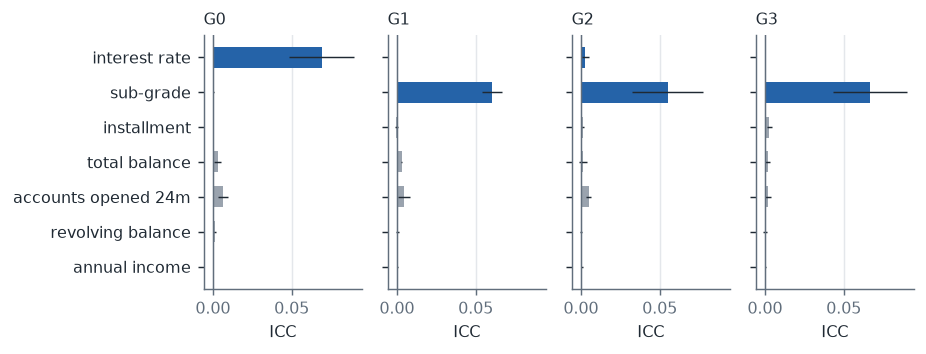

In [12]:
stability = []
for cohort, block in icc_mean.groupby(level='cohort'):
    for graph, row in block.droplevel('cohort').iterrows():
        order = row.sort_values(ascending=False)
        stability.append({'cohort': cohort, 'graph': graph, 'top_1': order.index[0], 'top_2': order.index[1],
                          'top_1_value': order.iloc[0],
                          'rank_int_rate': int(order.index.get_loc('int_rate')) + 1,
                          'rank_sg': int(order.index.get_loc('sg')) + 1})
display(save_table(pd.DataFrame(stability).round(4), 'table_icc_rank_stability', index=False))

labels = {'int_rate': 'interest rate', 'sg': 'sub-grade', 'installment': 'installment', 'tot_cur_bal': 'total balance',
          'acc_open_past_24mths': 'accounts opened 24m', 'revol_bal': 'revolving balance', 'annual_inc': 'annual income'}
plot = icc_mean.loc['natural'][list(labels)[::-1]]
err = icc_std.loc['natural'][list(labels)[::-1]]
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.8), sharex=True, sharey=True)
for ax, graph in zip(axes, plot.index):
    highlight = [BLUE if c in ('int_rate', 'sg') else GREY for c in plot.columns]
    ax.barh(range(plot.shape[1]), plot.loc[graph], xerr=err.loc[graph].fillna(0), color=highlight, height=.6,
            error_kw=dict(ecolor=INK, lw=.8))
    ax.axvline(0, color=MUTED, lw=.8)
    ax.set_yticks(range(plot.shape[1]), [labels[c] for c in plot.columns])
    ax.set_title(graph.split(':')[0], fontsize=9, loc='left')
    ax.set_xlabel('ICC')
fig.tight_layout(); save_fig(fig, 'fig_icc_by_graph'); plt.show()

### 6.0 Adding plausible confounders to the graphs

The seven-variable graphs omit variables that plausibly affect both grade and default. Here credit score, loan amount, and term are added with the edges `fico -> sub_grade`, `fico -> y`, `term -> sub_grade`, `term -> y`, `annual_inc -> loan_amnt`, `loan_amnt -> installment`, and `term -> installment`, while the orientation between rate and grade changes as before. This run uses the natural-prevalence cohort.

In [13]:
EXTRA_VARS = ['fico', 'loan_amnt', 'term']
EXTRA_EDGES = [('fico', 'sg'), ('fico', 'y'), ('term', 'sg'), ('term', 'y'), ('annual_inc', 'loan_amnt'),
               ('loan_amnt', 'installment'), ('term', 'installment')]
BASE_EDGES = [('revol_bal', 'tot_cur_bal'), ('acc_open_past_24mths', 'y'), ('tot_cur_bal', 'y'), ('installment', 'sg')]
EXTENDED = {
    'G0x: rate -> grade -> y': BASE_EDGES + EXTRA_EDGES + [('int_rate', 'sg'), ('sg', 'y')],
    'G1x: grade -> rate; grade -> y': BASE_EDGES + EXTRA_EDGES + [('sg', 'int_rate'), ('sg', 'y')],
    'G3x: grade -> rate; both -> y': BASE_EDGES + EXTRA_EDGES + [('sg', 'int_rate'), ('sg', 'y'), ('int_rate', 'y')],
}
extended_vars = ICC_VARS + EXTRA_VARS
extended_pool = df[df.year.isin([2013, 2014])][extended_vars + ['y']].dropna()

t0, records = time.time(), []
for name, edges in EXTENDED.items():
    for seed in ICC_SEEDS:
        s = extended_pool.sample(ICC_SAMPLE, random_state=seed).copy()
        s[extended_vars] = (s[extended_vars] - s[extended_vars].min()) / (s[extended_vars].max() - s[extended_vars].min())
        s['y'] = s.y.astype(str)
        icc = gcm.intrinsic_causal_influence(fit_scm(edges, s, seed), 'y')
        records.append({'graph': name, 'seed': seed, **{k: float(icc.get(k, 0)) for k in extended_vars}})
    print(f'{name}: {(time.time() - t0) / 60:.0f} min')
extended_icc = pd.DataFrame(records).groupby('graph')[extended_vars].agg(['mean', 'std'])
display(save_table(extended_icc.round(4), 'table_icc_extended'))

G0x: rate -> grade -> y: 4 min
G1x: grade -> rate; grade -> y: 8 min
G3x: grade -> rate; both -> y: 11 min


annual_inc         installment      int_rate  \
                                     mean     std        mean  std     mean   
graph                                                                         
G0x: rate -> grade -> y           -0.0000  0.0001      0.0000  0.0   0.0413   
G1x: grade -> rate; grade -> y     0.0003  0.0001      0.0001  0.0   0.0000   
G3x: grade -> rate; both -> y     -0.0001  0.0002     -0.0000  0.0   0.0005   

                                            sg         acc_open_past_24mths  \
                                   std    mean     std                 mean   
graph                                                                         
G0x: rate -> grade -> y         0.0042  0.0009  0.0011               0.0053   
G1x: grade -> rate; grade -> y  0.0000  0.0204  0.0055               0.0062   
G3x: grade -> rate; both -> y   0.0006  0.0112  0.0035               0.0040   

                                       revol_bal         tot_cur_bal          \
                                   std      mean     std        mean     std   
graph                                                                          
G0x: rate -> grade -> y         0.0060   -0.0006  0.0009      0.0062  0.0032   
G1x: grade -> rate; grade -> y  0.0032    0.0000  0.0009      0.0031  0.0013   
G3x: grade -> rate; both -> y   0.0024    0.0007  0.0010      0.0009  0.0014   

                                  fico         loan_amnt            term  \
                                  mean     std      mean     std    mean   
graph                                                                      
G0x: rate -> grade -> y         0.0028  0.0016    0.0000  0.0000  0.0081   
G1x: grade -> rate; grade -> y  0.0212  0.0030   -0.0006  0.0010  0.0415   
G3x: grade -> rate; both -> y   0.0139  0.0030    0.0010  0.0012  0.0269   

                                        
                                   std  
graph                                   
G0x: rate -> grade -> y         0.0072  
G1x: grade -> rate; grade -> y  0.0102  
G3x: grade -> rate; both -> y   0.0011

### 6.1 Falsification

**Null hypothesis of the permutation test:** the graph's local Markov violations are no fewer than those of a random node permutation of the same graph. A small p-value means the graph beats random permutations. It does not validate edge directions or causal effects, and the graphs in one Markov equivalence class cannot be separated by these tests. Violated constraints are listed for inspection.

A p-value of 0 means no permutation did as well, so it is reported as below 1 / permutations. The sensitivity table repeats the test with other sample sizes and another draw, because the verdict can depend on the power of the kernel tests. Sample size 2000 covers G0 and G2 only, to limit run time.

In [14]:
falsify_pool = icc_sample('natural', 0).copy()
falsify_pool['y'] = falsify_pool.y.astype(float)

def run_falsification(name, n, permutations, draw=0):
    sample = falsify_pool.sample(min(n, len(falsify_pool)), random_state=draw)
    result = falsify_graph(nx.DiGraph(GRAPHS[name]), sample, n_permutations=permutations, show_progress_bar=False)
    lmc = result.summary[FalsifyConst.VALIDATE_LMC]
    p = lmc[FalsifyConst.P_VALUE]
    row = {'graph': name, 'n': len(sample), 'draw': draw, 'permutations': permutations,
           'violated': lmc[FalsifyConst.GIVEN_VIOLATIONS], 'tests': lmc[FalsifyConst.N_TESTS],
           'permutation_p': p, 'p_reported': f'< {1 / permutations:.3f}' if p == 0 else f'{p:.3f}',
           'falsified_at_0.05': result.falsified,
           'share_in_MEC': np.mean(result.summary.get(FalsifyConst.MEC, [0]) or [0])}
    return row, lmc

rows, violations = [], []
for name in GRAPHS:
    row, lmc = run_falsification(name, 1000, 20 if FAST else 40)
    rows.append(row)
    for pair, (p, bad) in lmc[FalsifyConst.LOCAL_VIOLATION_INSIGHT].items():
        if bad:
            violations.append({'graph': name, 'node': pair[0], 'non_descendant': pair[1], 'p': round(float(p), 4)})
display(save_table(pd.DataFrame(rows).round(3), 'table_falsification', index=False))
display(save_table(pd.DataFrame(violations), 'table_lmc_violations', index=False))

,graph,n,draw,permutations,violated,tests,permutation_p,p_reported,falsified_at_0.05,share_in_MEC
0,G0: rate -> grade -> y,1000,0,40,17,37,0.075,0.075,True,0.0
1,G1: grade -> rate; grade -> y,1000,0,40,16,36,0.050,0.050,False,0.0
2,G2: grade -> rate -> y,1000,0,40,16,35,0.000,< 0.025,False,0.0
3,G3: grade -> rate; both -> y,1000,0,40,17,34,0.025,0.025,False,0.0


,graph,node,non_descendant,p
0,G0: rate -> grade -> y,annual_inc,tot_cur_bal,0.0000
1,G0: rate -> grade -> y,annual_inc,revol_bal,0.0167
2,G0: rate -> grade -> y,installment,tot_cur_bal,0.0008
3,G0: rate -> grade -> y,installment,int_rate,0.0000
4,G0: rate -> grade -> y,installment,revol_bal,0.0000
...,...,...,...,...
61,G3: grade -> rate; both -> y,y,annual_inc,0.0430
62,G3: grade -> rate; both -> y,sg,tot_cur_bal,0.0000
63,G3: grade -> rate; both -> y,sg,acc_open_past_24mths,0.0000
64,G3: grade -> rate; both -> y,sg,annual_inc,0.0000


In [15]:
# Sensitivity of the verdict to sample size and to the sample drawn.
G0_G2 = [g for g in GRAPHS if g.startswith(('G0', 'G2'))]
runs = [(g, 500, 20 if FAST else 40, 0) for g in GRAPHS]
if not FAST:
    runs += [(g, 1000, 40, 1) for g in GRAPHS]
    runs += [(g, 2000, 20, 0) for g in G0_G2]
t0 = time.time()
sensitivity = pd.DataFrame([run_falsification(*run)[0] for run in runs])
print(f'Falsification sensitivity: {(time.time() - t0) / 60:.0f} min')
display(save_table(sensitivity.round(3), 'table_falsification_sensitivity', index=False))

Falsification sensitivity: 93 min


,graph,n,draw,permutations,violated,tests,permutation_p,p_reported,falsified_at_0.05,share_in_MEC
0,G0: rate -> grade -> y,500,0,40,14,37,0.025,0.025,False,0.0
1,G1: grade -> rate; grade -> y,500,0,40,13,36,0.000,< 0.025,False,0.0
2,G2: grade -> rate -> y,500,0,40,13,35,0.025,0.025,False,0.0
3,G3: grade -> rate; both -> y,500,0,40,13,34,0.075,0.075,True,0.0
4,G0: rate -> grade -> y,1000,1,40,17,37,0.000,< 0.025,False,0.0
5,G1: grade -> rate; grade -> y,1000,1,40,15,36,0.000,< 0.025,False,0.0
6,G2: grade -> rate -> y,1000,1,40,15,35,0.000,< 0.025,False,0.0
7,G3: grade -> rate; both -> y,1000,1,40,15,34,0.050,0.050,False,0.0
8,G0: rate -> grade -> y,2000,0,20,21,37,0.000,< 0.050,False,0.0
9,G2: grade -> rate -> y,2000,0,20,22,35,0.050,0.050,False,0.0


### 6.2 Revisiting the earlier recourse experiment

This reproduces the earlier procedure on a 16,000 / 4,000 balanced split with the published graph. Four versions are compared on the same borderline loans:

- **A. Earlier procedure, levers unchanged:** every node fixed at the applicant's value.
- **B. Earlier procedure, levers reduced 25%:** every node fixed, with `installment` and `int_rate` lowered.
- **C. Levers reduced 25%, grade free to respond:** the same change, but `sub_grade` is generated by its mechanism.
- **D. Levers unchanged, grade free to respond:** `sub_grade` is generated by its mechanism with no lever change.

If A and B match, the earlier reductions did not come from the levers. C - D isolates the lever effect when grade responds, while D - A shows what freeing the grade does on its own. Each probability uses 1,000 simulated draws, so differences carry Monte Carlo noise, which is printed below.

In [16]:
from sklearn.model_selection import train_test_split

bal = pd.concat([df[df.y == k].sample(10_000, random_state=42) for k in (0, 1)])[ICC_VARS + ['y']]
bal = bal.fillna(bal.median())
bal_fit, bal_eval = train_test_split(bal, test_size=4000, random_state=42, stratify=bal.y)
lo, hi = bal_fit[ICC_VARS].min(), bal_fit[ICC_VARS].max()
scale = lambda frame: frame.assign(**{c: (frame[c] - lo[c]) / (hi[c] - lo[c]) for c in ICC_VARS})
bal_fit, bal_eval = scale(bal_fit), scale(bal_eval)

catboost_7 = CatBoostClassifier(iterations=250, learning_rate=0.06, depth=5, random_seed=42, verbose=0)
catboost_7.fit(bal_fit[ICC_VARS], bal_fit.y)
p_cat = catboost_7.predict_proba(bal_eval[ICC_VARS])[:, 1]

scm_g0 = fit_scm(GRAPHS['G0: rate -> grade -> y'], bal_fit.assign(y=bal_fit.y.astype(str)), 42)
LEVERS = ['installment', 'int_rate']

def simulate(row, reduce_levers, free_grade, n=1000):
    # Fixed-value lambdas mirror the earlier implementation of the intervention.
    interventions = {c: (lambda x, v=row[c]: v) for c in ICC_VARS}
    if reduce_levers:
        for c in LEVERS:
            interventions[c] = (lambda x, v=row[c] * 0.75: v)
    if free_grade:
        interventions.pop('sg')
    samples = gcm.interventional_samples(scm_g0, interventions, num_samples_to_draw=n)
    return (samples['y'].astype(str) == '1').mean()

borderline = np.where((p_cat >= 0.51) & (p_cat <= 0.68))[0]
rng = np.random.default_rng(0)
chosen = rng.choice(borderline, size=min(30 if FAST else 200, len(borderline)), replace=False)
rows = []
for i in chosen:
    row = bal_eval.iloc[i]
    rows.append({'catboost': p_cat[i], 'A_no_change': simulate(row, False, False),
                 'B_levers_fixed_grade': simulate(row, True, False), 'C_levers_free_grade': simulate(row, True, True),
                 'D_free_grade_only': simulate(row, False, True)})
artifact = pd.DataFrame(rows)
gaps = pd.DataFrame({
    'B - A': artifact.B_levers_fixed_grade - artifact.A_no_change,
    'C - A': artifact.C_levers_free_grade - artifact.A_no_change,
    'D - A': artifact.D_free_grade_only - artifact.A_no_change,
    'C - D': artifact.C_levers_free_grade - artifact.D_free_grade_only,
    'A - CatBoost': artifact.A_no_change - artifact.catboost,
})
summary = pd.DataFrame({'mean': gaps.mean(), 'std': gaps.std(), 'se_of_mean': gaps.sem(), 'share |gap| > 0.03': (gaps.abs() > .03).mean()})
display(save_table(summary.round(4), 'table_earlier_recourse_check'))
print(f'Borderline loans sampled: {len(artifact)}')
print(f'Monte Carlo std of a difference from noise alone: {np.sqrt((2 * artifact.A_no_change * (1 - artifact.A_no_change) / 1000).mean()):.4f}')
print(f'Under 50% with NO lever change, only by switching from CatBoost to the SCM: {(artifact.A_no_change < .5).mean():.1%}')
print(f'Under 50% after lever change in procedure B: {(artifact.B_levers_fixed_grade < .5).mean():.1%}')

import shap
shap_values = shap.TreeExplainer(catboost_7).shap_values(bal_eval[ICC_VARS])
icc_bal = icc_mean.loc['balanced']
compare = pd.DataFrame({'mean_abs_SHAP': np.abs(shap_values).mean(axis=0)}, index=ICC_VARS)
for name in GRAPHS:
    compare[f'ICC {name.split(":")[0]}'] = icc_bal.loc[name]
display(save_table(compare.round(4).sort_values('mean_abs_SHAP', ascending=False), 'table_shap_vs_icc'))

,mean,std,se_of_mean,share |gap| > 0.03
B - A,-0.0001,0.0230,0.0016,0.195
C - A,-0.0900,0.0442,0.0031,0.920
D - A,0.0015,0.0285,0.0020,0.320
C - D,-0.0915,0.0344,0.0024,0.970
A - CatBoost,-0.0068,0.0545,0.0039,0.595


Borderline loans sampled: 200
Monte Carlo std of a difference from noise alone: 0.0218
Under 50% with NO lever change, only by switching from CatBoost to the SCM: 5.0%
Under 50% after lever change in procedure B: 9.0%


,mean_abs_SHAP,ICC G0,ICC G1,ICC G2,ICC G3
sg,0.3946,0.0041,0.0922,0.0845,0.0950
acc_open_past_24mths,0.1623,0.0060,0.0065,0.0045,0.0052
int_rate,0.1301,0.1122,0.0000,0.0067,0.0003
tot_cur_bal,0.1199,0.0066,0.0056,0.0047,0.0054
annual_inc,0.1070,-0.0000,0.0018,0.0005,0.0012
installment,0.0983,-0.0000,0.0040,0.0027,0.0032
revol_bal,0.0638,0.0013,0.0012,0.0007,0.0010


## 7. RQ3: Population-level recourse

The flagging threshold is set in advance on the calibration period, not chosen on the test set. All policies use one calibrated model, so risk before and after the change is on one scale, and contract variables are recomputed in real units.

**Policies**

| Policy | Role |
|---|---|
| Loan amount -10/-20/-30%, grade held | Primary lever |
| Loan amount -10/-20/-30%, grade and rate re-derived | Primary lever, grade allowed to respond |
| Term 36 to 60, Term 60 to 36 | Secondary; repriced from the same-cell rate table |
| Rate -25% with payment recomputed | Extrapolation; rate has little independent support |
| Installment -25% and rate -25%, set independently | Earlier policy; contract not kept consistent |
| Loan amount -20% without recomputing payment | Uncoupled what-if on the predictive model |
| Grade relabelled 1 or 3 notches better, nothing else | **Negative control** |

Relabelling a grade changes no contract term and no borrower attribute, so success under it measures how readily the model's score can be moved without any real change. A lever must exceed it to count as a signal.

**Feasibility:** new amount of at least $1,000, and payment-to-income at or below the larger of the applicant's current value and the 95th percentile on the fit period. **Support:** new contract values within the 1st to 99th percentile observed in the same `sub_grade x quarter x term` cell.

In [17]:
from sklearn.ensemble import HistGradientBoostingRegressor

PTI_CAP = fit.pti.quantile(0.95)
RATE_TABLE = df.groupby(['sg', 'quarter', 'term']).int_rate.mean()
GRADE_FEATURES = PRE + ['loan_amnt', 'term', 'q_idx']
grade_model = HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(fit[GRADE_FEATURES], fit.sg)
support = df.groupby(['sg', 'quarter', 'term']).agg(
    amt_lo=('loan_amnt', lambda s: s.quantile(.01)), amt_hi=('loan_amnt', lambda s: s.quantile(.99)),
    rate_lo=('int_rate', lambda s: s.quantile(.01)), rate_hi=('int_rate', lambda s: s.quantile(.99)))

def lookup_rate(sg, quarter, term, fallback):
    rate = RATE_TABLE.reindex(pd.MultiIndex.from_arrays([sg, quarter, term])).values
    return np.where(np.isnan(rate), fallback, rate)

def rebuild(frame):
    frame['installment'] = annuity(frame.loan_amnt, frame.int_rate, frame.term)
    frame['pti'] = frame.installment * 12 / frame.annual_inc.clip(lower=1000)
    return frame

def change_contract(base, amount=1.0, term=None, respond=False):
    new = base.copy()
    new['loan_amnt'] = base.loan_amnt * amount
    if term is not None:
        new['term'] = float(term)
    if respond:
        shift = grade_model.predict(new[GRADE_FEATURES]) - grade_model.predict(base[GRADE_FEATURES])
        new['sg'] = np.clip(np.round(base.sg + shift), 0, 34)
    if term is not None or respond:
        new['int_rate'] = lookup_rate(new.sg.values, new.quarter.values, new.term.values, base.int_rate.values)
    return rebuild(new)

def in_support(new):
    s = support.reindex(pd.MultiIndex.from_arrays([new.sg.values, new.quarter.values, new.term.values]))
    return ((new.loan_amnt.values >= s.amt_lo.values) & (new.loan_amnt.values <= s.amt_hi.values)
            & (new.int_rate.values >= s.rate_lo.values - 1e-6) & (new.int_rate.values <= s.rate_hi.values + 1e-6))

def feasible(base, new):
    return ((new.loan_amnt.values >= MIN_LOAN)
            & (new.pti.values <= np.maximum(PTI_CAP, base.pti.values) + 1e-9))

def uncoupled(base, **changes):
    new = base.copy()
    for col, factor in changes.items():
        new[col] = base[col] * factor
    return new

def relabel(base, notches):
    return base.assign(sg=(base.sg - notches).clip(lower=0))

POLICIES = {
    'Control: grade relabel -1': ('control', lambda b: relabel(b, 1), None),
    'Control: grade relabel -3': ('control', lambda b: relabel(b, 3), None),
    'Amount -10%, grade held': ('lever', lambda b: change_contract(b, .9), None),
    'Amount -20%, grade held': ('lever', lambda b: change_contract(b, .8), None),
    'Amount -30%, grade held': ('lever', lambda b: change_contract(b, .7), None),
    'Amount -10%, grade responds': ('lever', lambda b: change_contract(b, .9, respond=True), None),
    'Amount -20%, grade responds': ('lever', lambda b: change_contract(b, .8, respond=True), None),
    'Amount -30%, grade responds': ('lever', lambda b: change_contract(b, .7, respond=True), None),
    'Term 36 to 60': ('term', lambda b: change_contract(b, term=60), 36),
    'Term 60 to 36': ('term', lambda b: change_contract(b, term=36), 60),
    'Rate -25%, payment recomputed': ('extrapolation', lambda b: rebuild(uncoupled(b, int_rate=.75)), None),
    'Earlier policy: installment and rate -25%': ('uncoupled', lambda b: uncoupled(b, installment=.75, int_rate=.75), None),
    'Amount -20%, payment not recomputed': ('uncoupled', lambda b: uncoupled(b, loan_amnt=.8), None),
    **{f'Control strength: grade relabel -{k}': ('dose', (lambda b, k=k: relabel(b, k)), None) for k in (2, 4, 5, 6)},
}

def evaluate(model, tau, flag_rate, data=None, policies=None):
    data = test if data is None else data
    flagged_mask = model.predict(data) > tau
    flagged = data[flagged_mask]
    base_p = model.predict(flagged)
    rng = np.random.default_rng(0)
    rows = []
    for name, (kind, policy, only_term) in (policies or POLICIES).items():
        mask = np.ones(len(flagged), bool) if only_term is None else (flagged.term == only_term).values
        base, p0 = flagged[mask], base_p[mask]
        new = policy(base)
        p1 = model.predict(new)
        ok = feasible(base, new) & new.loan_amnt.notna().values
        success = (p1 <= tau) & ok
        draws = rng.integers(0, len(base), (N_BOOT, len(base)))
        boot = success[draws].mean(axis=1)
        interest0 = base.installment * base.term - base.loan_amnt
        interest1 = new.installment * new.term - new.loan_amnt
        rows.append({'policy': name, 'kind': kind, 'flag_rate': flag_rate, 'tau': tau, 'n': len(base),
                     'feasible': ok.mean(), 'in_support': in_support(new).mean(),
                     'success': success.mean(), 'success_lo': np.quantile(boot, .025), 'success_hi': np.quantile(boot, .975),
                     'delta_risk': (p1 - p0).mean(), 'payment_change': (new.installment / base.installment - 1).mean(),
                     'interest_income_change': (interest1.sum() / interest0.sum() - 1),
                     'expected_default_exposure_change': ((p1 * new.loan_amnt).sum() / (p0 * base.loan_amnt).sum() - 1)})
    return pd.DataFrame(rows)

p_cal = risk.predict(cal)
results = pd.concat([evaluate(risk, np.quantile(p_cal, 1 - r), r) for r in FLAG_RATES], ignore_index=True)
save_table(results, 'table_recourse_all_thresholds', index=False)

tau_primary = np.quantile(p_cal, 1 - PRIMARY_FLAG_RATE)
flag = p_test > tau_primary
print(f'Threshold {tau_primary:.4f}: flagged {flag.sum():,} of {len(test):,} ({flag.mean():.1%}); '
      f'observed default {test.y[flag].mean():.3f} flagged vs {test.y[~flag].mean():.3f} not flagged')
primary = results[results.flag_rate == PRIMARY_FLAG_RATE].drop(columns=['flag_rate', 'tau']).set_index('policy')
display(primary.round(3))

Threshold 0.2700: flagged 17,383 of 82,211 (21.1%); observed default 0.354 flagged vs 0.146 not flagged


,kind,n,feasible,in_support,success,success_lo,success_hi,delta_risk,payment_change,interest_income_change,expected_default_exposure_change
policy,,,,,,,,,,,
Control: grade relabel -1,control,17383,1.000,0.004,0.048,0.045,0.052,-0.004,0.000,0.000,-0.012
Control: grade relabel -3,control,17383,1.000,0.000,0.146,0.141,0.151,-0.015,0.000,0.000,-0.040
"Amount -10%, grade held",lever,17383,1.000,0.935,0.090,0.086,0.095,-0.013,-0.100,-0.100,-0.134
"Amount -20%, grade held",lever,17383,1.000,0.859,0.174,0.168,0.179,-0.027,-0.200,-0.200,-0.261
"Amount -30%, grade held",lever,17383,1.000,0.797,0.262,0.256,0.269,-0.040,-0.300,-0.300,-0.381
"Amount -10%, grade responds",lever,17383,1.000,0.818,0.112,0.107,0.116,-0.016,-0.104,-0.119,-0.144
"Amount -20%, grade responds",lever,17383,1.000,0.750,0.209,0.204,0.215,-0.031,-0.206,-0.232,-0.278
"Amount -30%, grade responds",lever,17383,1.000,0.694,0.306,0.299,0.313,-0.045,-0.307,-0.337,-0.399
Term 36 to 60,term,4399,1.000,0.481,0.002,0.001,0.004,0.065,-0.298,0.736,0.197


In [18]:
# Term comparison on a common 36-month horizon, since 60-month loans are exposed for longer.
tau36 = np.quantile(risk36.predict(cal), 1 - PRIMARY_FLAG_RATE)
term_rows = evaluate(risk36, tau36, PRIMARY_FLAG_RATE)
term_rows = term_rows[term_rows.policy.str.startswith('Term') | term_rows.policy.eq('Control: grade relabel -3')]
display(save_table(term_rows.drop(columns=['flag_rate']).round(3), 'table_recourse_term_36m', index=False))

,policy,kind,tau,n,feasible,in_support,success,success_lo,success_hi,delta_risk,payment_change,interest_income_change,expected_default_exposure_change
1,Control: grade relabel -3,control,0.218,17495,1.000,0.000,0.139,0.134,0.143,-0.012,0.000,0.000,-0.042
8,Term 36 to 60,term,0.218,7685,1.000,0.451,0.101,0.095,0.107,-0.009,-0.302,0.733,-0.028
9,Term 60 to 36,term,0.218,9810,0.561,0.911,0.051,0.047,0.056,-0.001,0.406,-0.427,-0.013


### 7.1 How strong is the control?

Beating a relabel of a given size depends on that size. We therefore report success for relabels of 1 to 6 notches, express each contract change as an equivalent number of notches, and compare policies with controls on the same loans with a paired bootstrap.

In [19]:
flagged_test = test[p_test > tau_primary]
rng = np.random.default_rng(0)

def success_vector(policy):
    new = policy(flagged_test)
    return (risk.predict(new) <= tau_primary) & feasible(flagged_test, new)

notch_success = pd.Series({k: success_vector(lambda b, k=k: relabel(b, k)).mean() for k in range(1, 7)})
display(save_table(notch_success.rename('success').rename_axis('notches').round(4).to_frame(), 'table_control_strength'))

draws = rng.integers(0, len(flagged_test), (N_BOOT, len(flagged_test)))
rows = []
for factor in (.9, .8, .7):
    lever = success_vector(lambda b, f=factor: change_contract(b, f)).astype(float)
    row = {'amount_change': f'{factor - 1:+.0%}', 'success': lever.mean(),
           'equivalent_notches': np.interp(lever.mean(), notch_success.values, notch_success.index.values)}
    for k in (3, 4):
        gap = lever - success_vector(lambda b, k=k: relabel(b, k)).astype(float)
        boot = gap[draws].mean(axis=1)
        row |= {f'minus_relabel_{k}': gap.mean(), f'minus_relabel_{k}_lo': np.quantile(boot, .025),
                f'minus_relabel_{k}_hi': np.quantile(boot, .975)}
    rows.append(row)
display(save_table(pd.DataFrame(rows).round(4), 'table_paired_vs_control', index=False))

,success
notches,
1,0.0484
2,0.0966
3,0.1461
4,0.1916
5,0.2368
6,0.2853


,amount_change,success,equivalent_notches,minus_relabel_3,minus_relabel_3_lo,minus_relabel_3_hi,minus_relabel_4,minus_relabel_4_lo,minus_relabel_4_hi
0,-10%,0.0904,1.8699,-0.0557,-0.0603,-0.0515,-0.1012,-0.1061,-0.0960
1,-20%,0.1744,3.6228,0.0283,0.0237,0.0328,-0.0171,-0.0220,-0.0121
2,-30%,0.2623,5.5255,0.1162,0.1107,0.1223,0.0708,0.0649,0.0769


### 7.2 A second out-of-time window

The same procedure is repeated on an earlier matured window: fit on 2012, calibrate on 2013 H1, test on 2013 H2. This window is smaller and comes from different lending conditions.

In [20]:
fit_b = df[df.year == 2012]
cal_b = df[(df.year == 2013) & (df.month <= 6)]
test_b = df[(df.year == 2013) & (df.month > 6)]
risk_b = RiskModel(FEATURES, 'y', MODEL_SEEDS).fit(fit_b, cal_b)
print('Second window, loans fit / calibration / test:', len(fit_b), len(cal_b), len(test_b))
print({k: round(v, 4) for k, v in score(test_b.y, risk_b.predict(test_b)).items()})

KEEP = ['Control: grade relabel -3', 'Control strength: grade relabel -4', 'Amount -10%, grade held',
        'Amount -20%, grade held', 'Amount -30%, grade held', 'Term 60 to 36', 'Rate -25%, payment recomputed']
window_rows = [evaluate(risk_b, np.quantile(risk_b.predict(cal_b), 1 - r), r, data=test_b, policies={k: POLICIES[k] for k in KEEP})
               for r in FLAG_RATES]
display(save_table(pd.concat(window_rows, ignore_index=True).round(4), 'table_second_window', index=False))

Second window, loans fit / calibration / test: 30811 31893 48747
{'ROC-AUC': 0.693, 'PR-AUC': 0.2917, 'Brier': 0.1273, 'ECE': 0.0079, 'mean predicted': np.float64(0.1678), 'observed': np.float64(0.1622)}


,policy,kind,flag_rate,tau,n,feasible,in_support,success,success_lo,success_hi,delta_risk,payment_change,interest_income_change,expected_default_exposure_change
0,Control: grade relabel -3,control,0.1,0.2906,5182,1.0000,0.0012,0.1362,0.1270,0.1454,-0.0137,0.0000,0.0000,-0.0343
1,Control strength: grade relabel -4,dose,0.1,0.2906,5182,1.0000,0.0006,0.1781,0.1677,0.1888,-0.0179,0.0000,0.0000,-0.0452
2,"Amount -10%, grade held",lever,0.1,0.2906,5182,1.0000,0.9631,0.1283,0.1200,0.1369,-0.0110,-0.1000,-0.1000,-0.1327
3,"Amount -20%, grade held",lever,0.1,0.2906,5182,0.9998,0.9305,0.2377,0.2271,0.2497,-0.0208,-0.2000,-0.2000,-0.2534
4,"Amount -30%, grade held",lever,0.1,0.2906,5182,0.9996,0.8929,0.3171,0.3053,0.3310,-0.0285,-0.3000,-0.3000,-0.3632
5,Term 60 to 36,term,0.1,0.2906,4326,0.5062,0.8944,0.3793,0.3652,0.3955,-0.1083,0.3931,-0.4291,-0.3026
6,"Rate -25%, payment recomputed",extrapolation,0.1,0.2906,5182,1.0000,0.0000,0.3439,0.3302,0.3559,-0.0385,-0.0987,-0.2760,-0.1027
7,Control: grade relabel -3,control,0.2,0.2357,10066,1.0000,0.0007,0.1219,0.1158,0.1280,-0.0123,0.0000,0.0000,-0.0370
8,Control strength: grade relabel -4,dose,0.2,0.2357,10066,1.0000,0.0003,0.1618,0.1554,0.1691,-0.0164,0.0000,0.0000,-0.0493
9,"Amount -10%, grade held",lever,0.2,0.2357,10066,0.9997,0.9677,0.0842,0.0789,0.0897,-0.0087,-0.1000,-0.1000,-0.1299


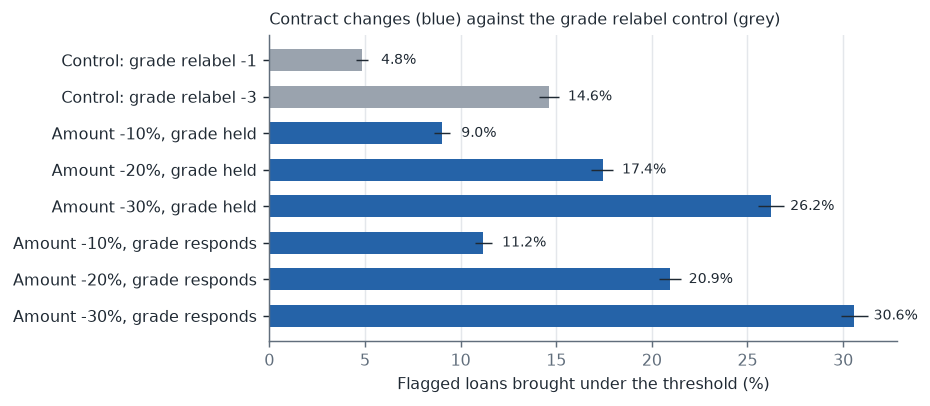

In [21]:
order = ['Control: grade relabel -1', 'Control: grade relabel -3', 'Amount -10%, grade held', 'Amount -20%, grade held',
         'Amount -30%, grade held', 'Amount -10%, grade responds', 'Amount -20%, grade responds', 'Amount -30%, grade responds']
plot = primary.loc[order[::-1]]
fig, ax = plt.subplots(figsize=(7.2, 3.2))
colors = [GREY if k == 'control' else BLUE for k in plot.kind]
ax.barh(plot.index, plot.success * 100, color=colors, height=.6,
        xerr=[(plot.success - plot.success_lo) * 100, (plot.success_hi - plot.success) * 100], error_kw=dict(ecolor=INK, lw=.8))
for y, value in enumerate(plot.success * 100):
    ax.text(value + 1, y, f'{value:.1f}%', va='center', fontsize=8)
ax.set_xlabel('Flagged loans brought under the threshold (%)')
ax.set_title('Contract changes (blue) against the grade relabel control (grey)', fontsize=9, loc='left')
fig.tight_layout(); save_fig(fig, 'fig_recourse_vs_control'); plt.show()

## 8. RQ4: Causal cross-check with DML

A partially linear model is cross-fitted on 2014 loans. For loan amount, nuisance models condition on borrower features, grade, term, and vintage.

The risk model's flag uses the loan amount, so restricting DML to those loans selects on the treatment. The main comparison therefore uses a second group flagged at the same rate by a model that sees only the borrower profile and vintage, and compares model and DML on those same loans. The treatment residual's mean is reported for each group: values away from zero indicate selection on the treatment. Two refutations are run: a permuted treatment residual, and an added random covariate. The E-value states how strong an unobserved confounder would need to be, on the risk-ratio scale, to explain the effect away.

In [22]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import KFold

dml_data = df[df.year == 2014].copy()
dml_data['log_amount'] = np.log(dml_data.loan_amnt)
dml_data['is_60'] = (dml_data.term == 60).astype(float)
dml_data['flagged'] = risk.predict(dml_data) > tau_primary
profile_risk = RiskModel(PRE + ['q_idx'], 'y', MODEL_SEEDS).fit(fit, cal)
tau_profile = np.quantile(profile_risk.predict(cal), 1 - PRIMARY_FLAG_RATE)
dml_data['flagged_profile'] = profile_risk.predict(dml_data) > tau_profile

def crossfit(data, treatment, outcome, X, folds=5, seed=0):
    ry, rt = np.zeros(len(data)), np.zeros(len(data))
    for a, b in KFold(folds, shuffle=True, random_state=seed).split(data):
        tr, te = data.iloc[a], data.iloc[b]
        ry[b] = te[outcome].values - HistGradientBoostingClassifier(max_iter=200, random_state=seed).fit(tr[X], tr[outcome]).predict_proba(te[X])[:, 1]
        rt[b] = te[treatment].values - HistGradientBoostingRegressor(max_iter=200, random_state=seed).fit(tr[X], tr[treatment]).predict(te[X])
    return ry, rt

def plr(ry, rt):
    theta = (rt * ry).sum() / (rt ** 2).sum()
    se = np.sqrt(((rt * (ry - theta * rt)) ** 2).sum()) / (rt ** 2).sum()
    return theta, se

def e_value(rr):
    rr = max(rr, 1 / rr)
    return rr + np.sqrt(rr * (rr - 1))

X_amount = PRE + ['sg', 'term', 'q_idx']
ry, rt = crossfit(dml_data, 'log_amount', 'y', X_amount)
scopes = {'All 2014 loans': np.ones(len(dml_data), bool), 'Flagged, borrower profile': dml_data.flagged_profile.values,
          'Flagged, risk model (selected on amount)': dml_data.flagged.values}
for label, grades in {'Grades A-B': (0, 9), 'Grades C-D': (10, 19), 'Grades E-G': (20, 34)}.items():
    scopes[label] = dml_data.sg.between(*grades).values

rows = []
for name, mask in scopes.items():
    theta, se = plr(ry[mask], rt[mask])
    base = dml_data.y.values[mask].mean()
    group = dml_data[mask]
    p_group = risk.predict(group)
    for factor in (.9, .8, .7):
        d = theta * np.log(factor)
        model_effect = (risk.predict(change_contract(group, factor)) - p_group).mean()
        d_null = (theta - 1.96 * se) * np.log(factor)  # the CI limit closest to zero when theta > 0
        rows.append({'scope': name, 'n': int(mask.sum()), 'treatment_resid_mean': rt[mask].mean(), 'amount_change': f'{factor - 1:+.0%}', 'theta': theta, 'se': se,
                     'model_effect': model_effect, 'model_to_dml': model_effect / d,
                     'model_to_dml_lo': model_effect / ((theta + 1.96 * se) * np.log(factor)),
                     'model_to_dml_hi': model_effect / d_null,
                     'effect_on_risk': d, 'ci_lo': (theta + 1.96 * se) * np.log(factor), 'ci_hi': d_null,
                     'e_value': e_value(base / (base + d)),
                     'e_value_ci': e_value(base / (base + d_null)) if d_null < 0 else 1.0})
dml_amount = pd.DataFrame(rows)
display(save_table(dml_amount.round(4), 'table_dml_amount', index=False))

rng = np.random.default_rng(1)
placebo = plr(ry, rng.permutation(rt))
noisy = dml_data.assign(random_covariate=rng.normal(size=len(dml_data)))
ry2, rt2 = crossfit(noisy, 'log_amount', 'y', X_amount + ['random_covariate'])
display(save_table(pd.DataFrame({'theta': [plr(ry, rt)[0], placebo[0], plr(ry2, rt2)[0]],
                                 'se': [plr(ry, rt)[1], placebo[1], plr(ry2, rt2)[1]]},
                                index=['estimate', 'placebo: permuted treatment residual', 'with random covariate']).round(4), 'table_dml_refutation'))

# Term: 60 vs 36 months on the common 36-month horizon, conditioning on grade as a pre-term score is not available.
ry_t, rt_t = crossfit(dml_data, 'is_60', 'y36', PRE + ['sg', 'loan_amnt', 'q_idx'])
theta_t, se_t = plr(ry_t, rt_t)
print(f'Term 60 vs 36, default within about 36 months: {theta_t:+.4f} (95% CI {theta_t - 1.96 * se_t:+.4f}, {theta_t + 1.96 * se_t:+.4f})')
print('Propensity of 60 months is taken from a regressor; overlap: residual std', round(float(rt_t.std()), 3))
pd.Series({'theta': theta_t, 'se': se_t}).to_csv(RESULTS / 'table_dml_term.csv')

,scope,n,treatment_resid_mean,amount_change,theta,se,model_effect,model_to_dml,model_to_dml_lo,model_to_dml_hi,effect_on_risk,ci_lo,ci_hi,e_value,e_value_ci
0,All 2014 loans,142995,-0.0000,-10%,0.0336,0.0024,-0.0048,1.3586,1.1947,1.5747,-0.0035,-0.0040,-0.0031,1.1595,1.1465
1,All 2014 loans,142995,-0.0000,-20%,0.0336,0.0024,-0.0098,1.3064,1.1487,1.5141,-0.0075,-0.0085,-0.0065,1.2503,1.2285
2,All 2014 loans,142995,-0.0000,-30%,0.0336,0.0024,-0.0146,1.2136,1.0671,1.4066,-0.0120,-0.0136,-0.0103,1.3389,1.3074
3,"Flagged, borrower profile",30242,-0.0014,-10%,0.0533,0.0062,-0.0082,1.4610,1.1903,1.8911,-0.0056,-0.0069,-0.0043,1.1587,1.1369
4,"Flagged, borrower profile",30242,-0.0014,-20%,0.0533,0.0062,-0.0169,1.4184,1.1556,1.8359,-0.0119,-0.0146,-0.0092,1.2490,1.2124
5,"Flagged, borrower profile",30242,-0.0014,-30%,0.0533,0.0062,-0.0253,1.3295,1.0831,1.7208,-0.0190,-0.0233,-0.0147,1.3370,1.2846
6,"Flagged, risk model (selected on amount)",29540,0.0893,-10%,0.0675,0.0092,-0.0124,1.7427,1.3761,2.3756,-0.0071,-0.0090,-0.0052,1.1666,1.1394
7,"Flagged, risk model (selected on amount)",29540,0.0893,-20%,0.0675,0.0092,-0.0252,1.6740,1.3219,2.2820,-0.0151,-0.0191,-0.0111,1.2624,1.2166
8,"Flagged, risk model (selected on amount)",29540,0.0893,-30%,0.0675,0.0092,-0.0379,1.5743,1.2431,2.1461,-0.0241,-0.0305,-0.0177,1.3565,1.2905
9,Grades A-B,54293,-0.0020,-10%,0.0157,0.0030,-0.0016,0.9889,0.7187,1.5848,-0.0016,-0.0023,-0.0010,1.1544,1.1181


,theta,se
estimate,0.0336,0.0024
placebo: permuted treatment residual,0.0018,0.0025
with random covariate,0.0335,0.0024


Term 60 vs 36, default within about 36 months: -0.0029 (95% CI -0.0092, +0.0034)
Propensity of 60 months is taken from a regressor; overlap: residual std 0.306


## 9. Decision rule

The rule and its thresholds were fixed before this full run, after a pilot. The pilot also informed the 3-notch control, so Section 7.1 reports other strengths. A contract policy counts as a supported signal only if all of the following hold:

1. **Beats the control:** the lower CI bound of its success rate is above the upper bound for the stronger grade relabel control.
2. **Direction agrees with DML:** the DML effect on loans flagged from the borrower profile is negative with a CI excluding zero.
3. **Has support:** at least 90% of new contracts fall within the observed range of their cell.
4. **Is feasible:** at least 90% satisfy the feasibility rule.

The table also shows the ratio between the risk reduction implied by the model and by DML. A large ratio means the model overstates the effect, even if the direction is right. DML conditions on grade, so its effect size and ratio are shown only for the grade-held policies. For grade-responds policies, criterion 2 still checks the direction of that estimate, but the sizes are not comparable.

In [23]:
control_hi = primary.loc['Control: grade relabel -3', 'success_hi']
flagged_dml = dml_amount[dml_amount.scope == 'Flagged, borrower profile'].set_index('amount_change')
rows = []
for name, row in primary[primary.kind.isin(['lever', 'term', 'extrapolation'])].iterrows():
    dml = None
    for tag in ['-10%', '-20%', '-30%']:
        if f'Amount {tag}' in name:
            dml = flagged_dml.loc[tag]
    comparable = dml is not None and 'grade held' in name
    rows.append({
        'policy': name, 'success': row.success, 'success_lo': row.success_lo, 'delta_risk_model': row.delta_risk,
        'delta_risk_dml': dml.effect_on_risk if comparable else np.nan,
        'model_to_dml_ratio': dml.model_to_dml if comparable else np.nan,
        'beats_control': row.success_lo > control_hi,
        'dml_agrees': (dml is not None) and (dml.ci_hi < 0),
        'in_support_90': row.in_support >= .9, 'feasible_90': row.feasible >= .9,
    })
decision = pd.DataFrame(rows)
decision['supported'] = decision[['beats_control', 'dml_agrees', 'in_support_90', 'feasible_90']].all(axis=1)
print(f'Control upper bound on success: {control_hi:.3f}')
display(save_table(decision.round(3), 'table_decision', index=False))

Control upper bound on success: 0.151


,policy,success,success_lo,delta_risk_model,delta_risk_dml,model_to_dml_ratio,beats_control,dml_agrees,in_support_90,feasible_90,supported
0,"Amount -10%, grade held",0.090,0.086,-0.013,-0.006,1.461,False,True,True,True,False
1,"Amount -20%, grade held",0.174,0.168,-0.027,-0.012,1.418,True,True,False,True,False
2,"Amount -30%, grade held",0.262,0.256,-0.040,-0.019,1.329,True,True,False,True,False
3,"Amount -10%, grade responds",0.112,0.107,-0.016,NaN,NaN,False,True,False,True,False
4,"Amount -20%, grade responds",0.209,0.204,-0.031,NaN,NaN,True,True,False,True,False
5,"Amount -30%, grade responds",0.306,0.299,-0.045,NaN,NaN,True,True,False,True,False
6,Term 36 to 60,0.002,0.001,0.065,NaN,NaN,False,False,False,True,False
7,Term 60 to 36,0.349,0.341,-0.076,NaN,NaN,True,False,True,False,False
8,"Rate -25%, payment recomputed",0.322,0.315,-0.040,NaN,NaN,True,False,False,True,False


### 9.1 The decision rule on the second window

Section 7.2 covers criteria 1, 3, and 4 for the 2013 window. This cell adds criterion 2 by repeating DML on 2013 loans with a borrower-profile flag fitted on the same earlier data, then applies all four criteria at the primary flag rate.

In [24]:
dml_b = df[df.year == 2013].copy()
dml_b['log_amount'] = np.log(dml_b.loan_amnt)
profile_b = RiskModel(PRE + ['q_idx'], 'y', MODEL_SEEDS).fit(fit_b, cal_b)
flag_b = profile_b.predict(dml_b) > np.quantile(profile_b.predict(cal_b), 1 - PRIMARY_FLAG_RATE)
ry_b, rt_b = crossfit(dml_b, 'log_amount', 'y', X_amount)
theta_b, se_b = plr(ry_b[flag_b], rt_b[flag_b])
group_b, base_b = dml_b[flag_b], dml_b.y.values[flag_b].mean()
p_group_b = risk_b.predict(group_b)
primary_b = window_rows[FLAG_RATES.index(PRIMARY_FLAG_RATE)].set_index('policy')
control_hi_b = primary_b.loc['Control: grade relabel -3', 'success_hi']

rows = []
for factor in (.9, .8, .7):
    d, d_null = theta_b * np.log(factor), (theta_b - 1.96 * se_b) * np.log(factor)
    model_effect = (risk_b.predict(change_contract(group_b, factor)) - p_group_b).mean()
    row = primary_b.loc[f'Amount {factor - 1:+.0%}, grade held']
    rows.append({'amount_change': f'{factor - 1:+.0%}', 'n_dml': len(group_b), 'treatment_resid_mean': rt_b[flag_b].mean(),
                 'theta': theta_b, 'se': se_b, 'effect_on_risk': d, 'ci_lo': (theta_b + 1.96 * se_b) * np.log(factor), 'ci_hi': d_null,
                 'model_effect': model_effect, 'model_to_dml': model_effect / d,
                 'e_value_ci': e_value(base_b / (base_b + d_null)) if d_null < 0 else 1.0,
                 'success': row.success, 'in_support': row.in_support,
                 'beats_control': row.success_lo > control_hi_b, 'dml_agrees': d_null < 0,
                 'in_support_90': row.in_support >= .9, 'feasible_90': row.feasible >= .9})
decision_b = pd.DataFrame(rows)
decision_b['supported'] = decision_b[['beats_control', 'dml_agrees', 'in_support_90', 'feasible_90']].all(axis=1)
display(save_table(decision_b.round(4), 'table_decision_second_window', index=False))

,amount_change,n_dml,treatment_resid_mean,theta,se,effect_on_risk,ci_lo,ci_hi,model_effect,model_to_dml,e_value_ci,success,in_support,beats_control,dml_agrees,in_support_90,feasible_90,supported
0,-10%,15492,-0.007,0.0442,0.0084,-0.0047,-0.0064,-0.0029,-0.0058,1.2458,1.1181,0.0842,0.9677,False,True,True,True,False
1,-20%,15492,-0.007,0.0442,0.0084,-0.0099,-0.0135,-0.0062,-0.0118,1.1941,1.1816,0.1631,0.9385,True,True,True,True,True
2,-30%,15492,-0.007,0.0442,0.0084,-0.0158,-0.0216,-0.0099,-0.0164,1.0437,1.2412,0.2313,0.9035,True,True,True,True,True


### 9.2 How strong would an unobserved confounder need to be?

*Added on 2026-11-04, after the main results; the design below was fixed before this cell was first run.*

The E-value says how strong an unobserved confounder must be, on the risk-ratio scale with both loan amount and default, to move the DML interval to zero. On its own it does not say whether that strength is plausible. We benchmark it against the observed covariates on the profile-flagged 2014 loans in two ways:

1. **Marginal risk ratios.** Each covariate is split at its median (above vs not above). We compute its risk ratio with default and with an above-median loan amount, taking the larger direction. A covariate whose smaller ratio exceeds the E-value would be strong enough, if it were unobserved, to explain away the interval. These ratios are not adjusted for the other covariates, so they overstate what an unobserved variable would add beyond them.
2. **Leave one out.** DML is refitted without each covariate in turn. The shift in the effect of a 20% amount cut shows how much each observed variable moves the estimate. Dropping one of several correlated covariates understates their joint role, so this is a lower bound on what a comparable omitted variable could do.

In [25]:
flag_p = dml_data.flagged_profile.values
group = dml_data[flag_p]
theta_full, se_full = plr(ry[flag_p], rt[flag_p])
effect_full = theta_full * np.log(.8)
ci_hi_full = (theta_full - 1.96 * se_full) * np.log(.8)
e_value_ci = dml_amount.set_index(['scope', 'amount_change']).loc[('Flagged, borrower profile', '-20%'), 'e_value_ci']
amount_high = (group.log_amount > group.log_amount.median()).values

def risk_ratio(event, exposed):
    a, b = event[exposed].mean(), event[~exposed].mean()
    return max(a / b, b / a)

t0 = time.time()
rows = []
for z in X_amount:
    values = group[z]
    high = (values > values.median()).values
    if not high.any():
        high = (values >= values.median()).values
    if high.all() or not high.any():
        continue
    ry_z, rt_z = crossfit(dml_data, 'log_amount', 'y', [x for x in X_amount if x != z])
    theta_z, se_z = plr(ry_z[flag_p], rt_z[flag_p])
    rr_y, rr_d = risk_ratio(group.y.values, high), risk_ratio(amount_high, high)
    rows.append({'covariate': z, 'share_above_median': high.mean(), 'rr_default': rr_y, 'rr_amount': rr_d,
                 'min_rr': min(rr_y, rr_d), 'exceeds_e_value': min(rr_y, rr_d) >= e_value_ci,
                 'effect_without': theta_z * np.log(.8), 'ci_hi_without': (theta_z - 1.96 * se_z) * np.log(.8),
                 'shift': theta_z * np.log(.8) - effect_full})
benchmark = pd.DataFrame(rows).sort_values('min_rr', ascending=False)
display(save_table(benchmark.round(4), 'table_confounding_benchmark', index=False))

toward_zero = benchmark['shift'].clip(lower=0)
worst = benchmark.loc[toward_zero.idxmax()]
print(f'Effect of a 20% cut on profile-flagged loans: {effect_full * 100:+.2f} pp (CI upper bound {ci_hi_full * 100:+.2f} pp), '
      f'E-value of the CI bound {e_value_ci:.2f}')
print(f'Covariates whose smaller marginal risk ratio exceeds the E-value: {int(benchmark.exceeds_e_value.sum())} of {len(benchmark)}')
print(f'Largest leave-one-out shift toward zero: {worst.covariate} ({worst["shift"] * 100:+.2f} pp); '
      f'CI upper bound after an extra shift of that size: {(ci_hi_full + worst["shift"]) * 100:+.2f} pp')
print(f'{time.time() - t0:.0f}s')

,covariate,share_above_median,rr_default,rr_amount,min_rr,exceeds_e_value,effect_without,ci_hi_without,shift
15,term,0.3605,1.6325,2.3923,1.6325,True,-0.0172,-0.0146,-0.0053
14,sg,0.4960,1.5886,1.5864,1.5864,True,-0.0143,-0.0116,-0.0024
1,dti,0.5000,1.1234,1.1395,1.1234,False,-0.0122,-0.0095,-0.0003
4,home,0.4152,1.1137,1.2758,1.1137,False,-0.0115,-0.0088,0.0004
10,mort_acc,0.4354,1.0861,1.3602,1.0861,False,-0.0118,-0.0091,0.0001
12,acc_open_past_24mths,0.4446,1.0802,1.1252,1.0802,False,-0.0100,-0.0074,0.0019
6,revol_bal,0.5000,1.0605,2.3988,1.0605,False,-0.0103,-0.0078,0.0016
8,open_acc,0.4941,1.0588,1.4531,1.0588,False,-0.0115,-0.0088,0.0004
7,revol_util,0.4982,1.0567,1.3890,1.0567,False,-0.0115,-0.0088,0.0004
2,fico,0.4633,1.0511,1.1145,1.0511,False,-0.0112,-0.0085,0.0007


Effect of a 20% cut on profile-flagged loans: -1.19 pp (CI upper bound -0.92 pp), E-value of the CI bound 1.21
Covariates whose smaller marginal risk ratio exceeds the E-value: 2 of 17
Largest leave-one-out shift toward zero: acc_open_past_24mths (+0.19 pp); CI upper bound after an extra shift of that size: -0.73 pp
206s


### 9.3 Individual minimal recourse within data support

*Added on 2026-11-04, after the main results; the design below was fixed before this cell was first run.*

In the 2014 window the uniform amount cuts fail only the support criterion. A uniform cut also asks every flagged borrower for the same change, which is not how recourse is usually framed. Here each flagged loan gets the smallest cut, in steps of 5%, that brings its risk under the threshold while the new contract stays feasible and inside the observed range of its cell, with grade held. The cap on the cut is 20% (primary, to match the uniform policy) or 30%.

The model's score is not monotone in the amount, so searching over cuts would let a loan succeed at a cut where the score dips by chance, an advantage the single-shot control does not get. A smoke run showed this, and the rule was tightened before the full run: a cut counts only if risk stays under the threshold at that cut and at every larger cut up to the cap. Without the support constraint, success then equals the uniform cut at the cap, which the table reports as `success_unconstrained`.

Support is now a constraint rather than a criterion, so criterion 3 holds by construction. What matters is what it costs: how much success is lost against the same cap without the constraint, and whether the remainder still beats the grade relabel control (criterion 1). Criterion 2 is the DML estimate already reported for the same window.

We also report a **deflated** success rate, in which each loan's model-implied risk change is divided by the model-to-DML ratio for a 20% cut in that window (1.42 in 2014). This asks how many loans would still cross the threshold if the model overstated the effect for every loan by the average amount. It is a rough correction, not a causal estimate per loan.

In [26]:
def minimal_recourse(model, tau, data, cap, ratio, step=.05):
    flagged = data[model.predict(data) > tau]
    p0 = model.predict(flagged)
    # Walk from the cap toward smaller cuts. A cut counts only while risk has stayed under the
    # threshold at every larger cut, so a chance dip of the score at one cut is not a success.
    hit_sup, hit_deflated = np.zeros(len(flagged), bool), np.zeros(len(flagged), bool)
    run, run_deflated = np.ones(len(flagged), bool), np.ones(len(flagged), bool)
    chosen = np.full(len(flagged), np.nan)
    for i, factor in enumerate(np.round(np.arange(1 - cap, 1 - step + 1e-9, step), 2)):
        new = change_contract(flagged, factor)
        p1 = model.predict(new)
        ok, sup = feasible(flagged, new), in_support(new)
        run &= (p1 <= tau) & ok
        run_deflated &= (p0 + (p1 - p0) / ratio <= tau) & ok
        if i == 0:
            hit_any = run.copy()  # equals the uniform cut at the cap
        chosen[run & sup] = factor
        hit_sup |= run & sup
        hit_deflated |= run_deflated & sup
    return flagged, chosen, hit_any, hit_sup, hit_deflated

def relabel_success(model, tau, flagged, notches):
    return model.predict(relabel(flagged, notches)) <= tau

def boot_ci(x, draws):
    boot = x[draws].mean(axis=1)
    return np.quantile(boot, .025), np.quantile(boot, .975)

windows = {
    '2014 H2': (risk, tau_primary, test, flagged_dml.loc['-20%', 'model_to_dml'], flagged_dml.loc['-20%', 'ci_hi'] < 0),
    '2013 H2': (risk_b, np.quantile(risk_b.predict(cal_b), 1 - PRIMARY_FLAG_RATE), test_b,
                decision_b.set_index('amount_change').loc['-20%', 'model_to_dml'], bool(decision_b.dml_agrees.iloc[1])),
}
rows = []
for window, (model, tau, data, ratio, dml_agrees) in windows.items():
    for cap in (.2, .3):
        flagged, chosen, hit_any, hit_sup, hit_deflated = minimal_recourse(model, tau, data, cap, ratio)
        rng = np.random.default_rng(0)
        draws = rng.integers(0, len(flagged), (N_BOOT, len(flagged)))
        notches = pd.Series({k: relabel_success(model, tau, flagged, k).mean() for k in range(1, 7)})
        controls = {k: relabel_success(model, tau, flagged, k).astype(float) for k in (3, 4)}
        new_amount = np.where(hit_sup, flagged.loan_amnt * np.nan_to_num(chosen, nan=1.0), flagged.loan_amnt)
        row = {'window': window, 'cap': f'{cap:.0%}', 'n_flagged': len(flagged),
               'success_unconstrained': hit_any.mean(), 'success': hit_sup.mean()}
        row['success_lo'], row['success_hi'] = boot_ci(hit_sup.astype(float), draws)
        row['success_deflated'] = hit_deflated.mean()
        row['success_deflated_lo'], row['success_deflated_hi'] = boot_ci(hit_deflated.astype(float), draws)
        row['equivalent_notches'] = np.interp(hit_sup.mean(), notches.values, notches.index.values)
        for k, control in controls.items():
            gap = hit_sup - control
            row[f'minus_relabel_{k}'] = gap.mean()
            row[f'minus_relabel_{k}_lo'], row[f'minus_relabel_{k}_hi'] = boot_ci(gap, draws)
        control_hi = boot_ci(controls[3], draws)[1]
        row |= {'median_cut_if_success': 1 - np.nanmedian(chosen), 'mean_cut_if_success': 1 - np.nanmean(chosen),
                'volume_change': new_amount.sum() / flagged.loan_amnt.sum() - 1, 'model_to_dml_used': ratio,
                'beats_control': row['success_lo'] > control_hi, 'dml_agrees': dml_agrees,
                'deflated_beats_control': row['success_deflated_lo'] > control_hi}
        rows.append(row)
minimal = pd.DataFrame(rows)
display(save_table(minimal.round(4), 'table_minimal_recourse', index=False))

,window,cap,n_flagged,success_unconstrained,success,success_lo,success_hi,success_deflated,success_deflated_lo,success_deflated_hi,...,minus_relabel_4,minus_relabel_4_lo,minus_relabel_4_hi,median_cut_if_success,mean_cut_if_success,volume_change,model_to_dml_used,beats_control,dml_agrees,deflated_beats_control
0,2014 H2,20%,17383,0.1744,0.1650,0.1598,0.1708,0.1145,0.1099,0.1193,...,-0.0266,-0.0318,-0.0215,0.10,0.1225,-0.0200,1.4184,True,True,False
1,2014 H2,30%,17383,0.2623,0.2411,0.2346,0.2476,0.1663,0.1606,0.1721,...,0.0495,0.0441,0.0553,0.15,0.1721,-0.0424,1.4184,True,True,True
2,2013 H2,20%,10066,0.1631,0.1583,0.1511,0.1655,0.1332,0.1267,0.1394,...,-0.0036,-0.0107,0.0032,0.15,0.1259,-0.0205,1.1941,True,True,False
3,2013 H2,30%,10066,0.2313,0.2178,0.2102,0.2262,0.1816,0.1742,0.1895,...,0.0559,0.0488,0.0641,0.20,0.1748,-0.0407,1.1941,True,True,True


## 10. Limitations

- **Funded loans only.** Results do not extend to applicants who were rejected by LendingClub.
- **Unobserved confounding.** Loan amount is chosen by the borrower. DML adjusts for observed variables only; the E-values indicate how much confounding could change the conclusion.
- **Term comparisons.** Borrowers choosing 60 months differ in ways that may not be observed, and grade already reflects the term. The full-term label also gives 60-month loans a longer exposure window, so term results should be read against the 36-month label.
- **Graph evidence.** Falsification tests do not separate edge directions, and discovery on nearly deterministic variables is unreliable. The graphs are assumptions to compare, not validated structures.
- **Vintage scope.** Using matured vintages limits the conclusions to 2012-2014 lending conditions, even with the second window.
- **Partial model.** Grade re-derivation uses a regression approximation, since LendingClub's scoring model is not public.